In [1]:
!rm -rf sample_data

=== Mini-Batch Gradient Descent Results ===
Loss: 0.6817
Accuracy: 0.5970
Precision: 0.5000
Recall: 0.2222
F1: 0.3077


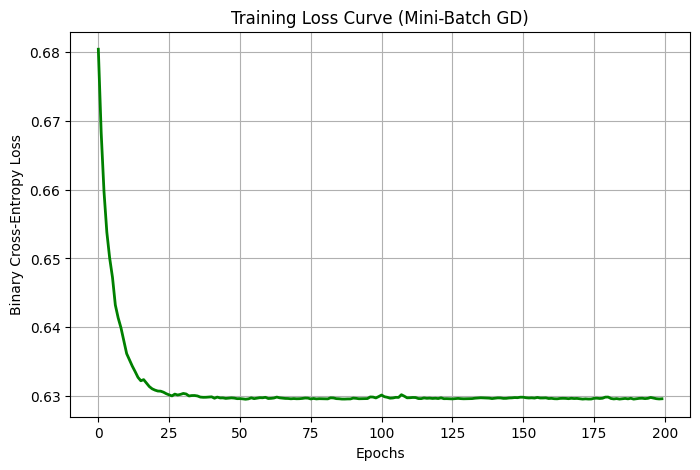

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load Data & Preprocessing (Titanic Dataset)
df = pd.read_csv('tested.csv')

features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
df = df[features + ['Survived']].dropna()

X = df[features].values
y = df['Survived'].values.reshape(-1, 1)

# Train / Test Split
np.random.seed(42)
indices = np.random.permutation(len(X))
split = int(0.8 * len(X))
X_train, X_test = X[indices[:split]], X[indices[split:]]
y_train, y_test = y[indices[:split]], y[indices[split:]]

# Standardization
mean = X_train.mean(axis=0)
std = X_train.std(axis=0) + 1e-8
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# Add Bias Term
X_train = np.c_[np.ones((X_train.shape[0], 1)), X_train]
X_test = np.c_[np.ones((X_test.shape[0], 1)), X_test]

# 2. Helper Functions
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def compute_loss(y_true, y_pred):
    eps = 1e-15
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

def evaluate_metrics(y_true, y_prob):
    y_pred = (y_prob >= 0.5).astype(int)
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    return {
        "Loss": compute_loss(y_true, y_prob),
        "Accuracy": (tp + tn) / len(y_true),
        "Precision": tp / (tp + fp + 1e-15),
        "Recall": tp / (tp + fn + 1e-15),
        "F1": 2 * tp / (2 * tp + fp + fn + 1e-15)
    }

# 3. Mini-Batch Gradient Descent Training & Tracking Loss
m, n = X_train.shape
w = np.zeros((n, 1))
lr = 0.05
batch_size = 32
epochs = 200
loss_history = []  # لتخزين قيمة الـ Loss بعد كل Epoch

for epoch in range(epochs):
    indices = np.random.permutation(m)
    X_train_shuffled = X_train[indices]
    y_train_shuffled = y_train[indices]

    for i in range(0, m, batch_size):
        xb = X_train_shuffled[i:i+batch_size]
        yb = y_train_shuffled[i:i+batch_size]

        y_pred = sigmoid(xb @ w)
        grad = (1 / len(xb)) * (xb.T @ (y_pred - yb))
        w -= lr * grad

    # حساب وتخزين الـ Loss على كامل بيانات التدريب بعد كل Epoch
    epoch_preds = sigmoid(X_train @ w)
    current_loss = compute_loss(y_train, epoch_preds)
    loss_history.append(current_loss)

# 4. Evaluation & Results
test_probs = sigmoid(X_test @ w)
results = evaluate_metrics(y_test, test_probs)

print("=== Mini-Batch Gradient Descent Results ===")
for k, v in results.items():
    print(f"{k}: {v:.4f}")

# 5. Plotting Loss Curve
plt.figure(figsize=(8, 5))
plt.plot(range(epochs), loss_history, color='green', linewidth=2)
plt.title('Training Loss Curve (Mini-Batch GD)')
plt.xlabel('Epochs')
plt.ylabel('Binary Cross-Entropy Loss')
plt.grid(True)
plt.show()